In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('energy_data.csv')
df.head()

,timestamp,household_id,energy_consumption_kWh,future_consumption_kWh
0,2024-01-01 00:00:00,1,0.208866,0.202300
1,2024-01-01 00:05:00,1,0.202300,0.262950
2,2024-01-01 00:10:00,1,0.262950,0.230617
3,2024-01-01 00:15:00,1,0.230617,0.259931
4,2024-01-01 00:20:00,1,0.259931,0.237530


In [62]:
#  نعرف عدد الصفوف والأعمدة
print("Shape of data:", df.shape)

# هنا عشان نشوف تفاصيل الأعمدة وأنواع البيانات والقيم المفقودة
df.info()

# نتأكد انه مافيه Missing Values
print("\nMissing values in each column:")
print(df.isnull().sum())

Shape of data: (921, 4)
<class 'pandas.DataFrame'>
RangeIndex: 921 entries, 0 to 920
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               921 non-null    str    
 1   household_id            921 non-null    int64  
 2   energy_consumption_kWh  921 non-null    float64
 3   future_consumption_kWh  921 non-null    float64
dtypes: float64(2), int64(1), str(1)
memory usage: 28.9 KB

Missing values in each column:
timestamp                 0
household_id              0
energy_consumption_kWh    0
future_consumption_kWh    0
dtype: int64


In [63]:
# إزالة أي مسافات زائدة في أسماء الأعمدة
df.columns = df.columns.str.strip()

# طباعة أسماء الأعمدة للتأكد منها
print(df.columns)

Index(['timestamp', 'household_id', 'energy_consumption_kWh',
       'future_consumption_kWh'],
      dtype='str')


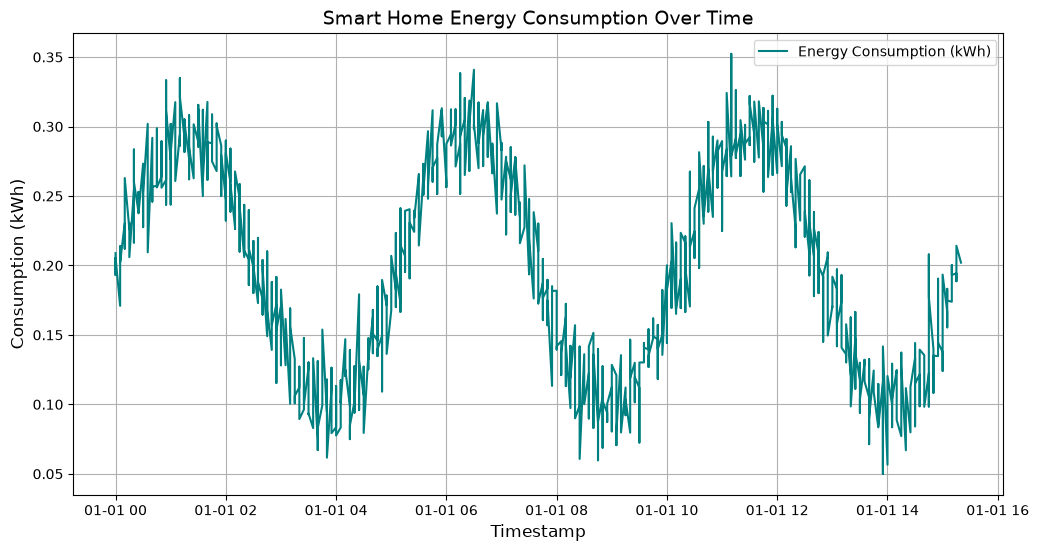

In [64]:
# نحول عمود الوقت timestamp إلى صيغة   
df['timestamp'] = pd.to_datetime(df['timestamp'])

# ترتيب البيانات بناءً على الوقت
df = df.sort_values('timestamp')

# رسم خط زمني يوضح استهلاك الطاقة Energy Consumption
plt.figure(figsize=(12, 6))
plt.plot(df['timestamp'], df['energy_consumption_kWh'], color='teal', label='Energy Consumption (kWh)')
plt.title('Smart Home Energy Consumption Over Time', fontsize=14)
plt.xlabel('Timestamp', fontsize=12)
plt.ylabel('Consumption (kWh)', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

In [65]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# تحديد المتغيرات المستقلة Features و Target
X = df[['energy_consumption_kWh', 'household_id']]
y = df['future_consumption_kWh']

# تقسيم البيانات إلى بيانات تدريب واختبار بنسبة 80% لـ 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# إنشاء نموذج ال Linear Regression
model = LinearRegression()

# تدريب النموذج على البيانات
model.fit(X_train, y_train)

# التنبؤ باستخدام بيانات الاختبار
y_pred = model.predict(X_test)

# هنا تقييم أداء النموذج
print("--- Model Performance ---")
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))

--- Model Performance ---
R2 Score: 0.8510992552356954
Mean Squared Error (MSE): 0.0008403851643634371
